## Step 1 — Install and import libraries

In [ ]:
%pip -q install ucimlrepo scikit-learn pandas numpy matplotlib seaborn joblib


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)

RANDOM_STATE = 42


## Step 2 — Collect the UCI Heart Disease dataset


In [ ]:
heart = fetch_ucirepo(id=45)

X_all = heart.data.features.copy()
y_raw = heart.data.targets.copy()

print("Dataset shape:", X_all.shape)
print("\nFeature columns:")
print(X_all.columns.tolist())
print("\nFirst five rows:")
display(X_all.head())
print("\nTarget preview:")
display(y_raw.head())


Dataset shape: (303, 13)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

First five rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0



Target preview:


,num
0,0
1,2
2,1
3,0
4,0


## Step 3 — Understand the data


In [ ]:
print("Dataset information:")
display(X_all.info())

print("\nMissing values per feature:")
display(X_all.isna().sum().sort_values(ascending=False))

target_col = y_raw.columns[0]
print("\nOriginal target distribution:")
display(y_raw[target_col].value_counts(dropna=False).sort_index())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 13 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
dtypes: float64(3), int64(10)
memory usage: 30.9 KB


None


Missing values per feature:


,0
ca,4
thal,2
cp,0
sex,0
age,0
chol,0
trestbps,0
fbs,0
restecg,0
exang,0



Original target distribution:


,count
num,
0,164
1,55
2,36
3,35
4,13


## Step 4 — Select exactly four input attributes and prepare the target


In [ ]:
required_features = ["age", "sex", "cp", "thalach"]
missing_features = [c for c in required_features if c not in X_all.columns]
if missing_features:
    raise ValueError(
        f"Expected columns {required_features}, but these were not found. "
        f"Available columns: {X_all.columns.tolist()}"
    )

X = X_all[required_features].copy()

# Convert possible '?' strings to NaN, then convert selected features to numeric.
X = X.replace("?", np.nan)
for col in required_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

y_numeric = pd.to_numeric(y_raw[target_col].replace("?", np.nan), errors="coerce")
valid_rows = y_numeric.notna()
X = X.loc[valid_rows].copy()
y_numeric = y_numeric.loc[valid_rows]

y = (y_numeric > 0).astype(int)

print("Selected input features (exactly four):", X.columns.tolist())
print("X shape:", X.shape)
print("Target counts (0 = no disease, 1 = disease present):")
display(y.value_counts().rename(index={0:"No disease", 1:"Disease present"}))
display(X.head())


Selected input features (exactly four): ['age', 'sex', 'cp', 'thalach']
X shape: (303, 4)
Target counts (0 = no disease, 1 = disease present):


,count
num,
No disease,164
Disease present,139


,age,sex,cp,thalach
0,63,1,1,150
1,67,1,4,108
2,67,1,4,129
3,37,1,3,187
4,41,0,2,172


## Step 5 — Explore the selected attributes


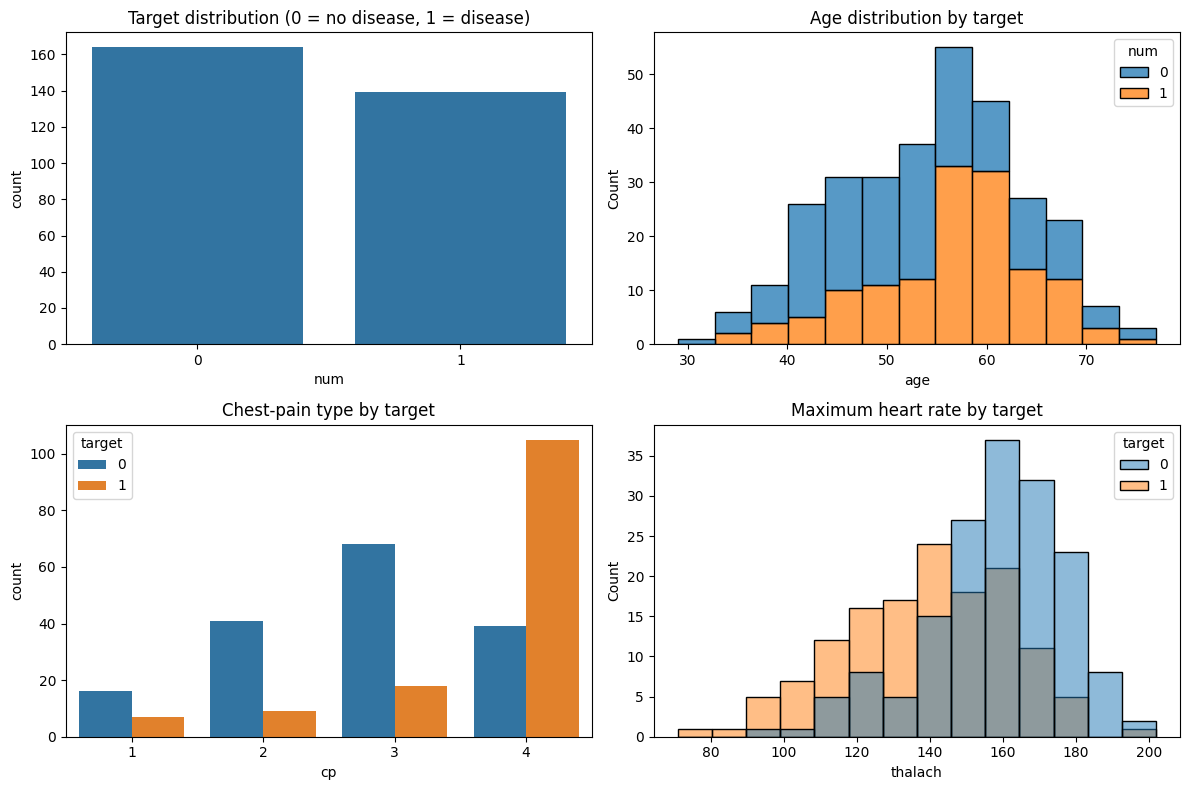

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.countplot(x=y, ax=axes[0, 0])
axes[0, 0].set_title("Target distribution (0 = no disease, 1 = disease)")

sns.histplot(data=X, x="age", hue=y, multiple="stack", ax=axes[0, 1])
axes[0, 1].set_title("Age distribution by target")

sns.countplot(data=X.assign(target=y), x="cp", hue="target", ax=axes[1, 0])
axes[1, 0].set_title("Chest-pain type by target")

sns.histplot(data=X.assign(target=y), x="thalach", hue="target", multiple="layer", ax=axes[1, 1])
axes[1, 1].set_title("Maximum heart rate by target")

plt.tight_layout()
plt.show()


## Step 6 — Split data into training and testing sets


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("Training target proportions:")
display(y_train.value_counts(normalize=True).rename("proportion"))


Training examples: 242
Testing examples: 61
Training target proportions:


,proportion
num,
0,0.541322
1,0.458678


## Step 7 — Preprocess and train the model


In [ ]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
print("Training completed.")


Training completed.


## Step 8 — Evaluate the model


Accuracy : 0.787
Precision: 0.800
Recall   : 0.714
F1-score : 0.755
ROC-AUC  : 0.856

Classification report:
                 precision    recall  f1-score   support

     No disease       0.78      0.85      0.81        33
Disease present       0.80      0.71      0.75        28

       accuracy                           0.79        61
      macro avg       0.79      0.78      0.78        61
   weighted avg       0.79      0.79      0.79        61



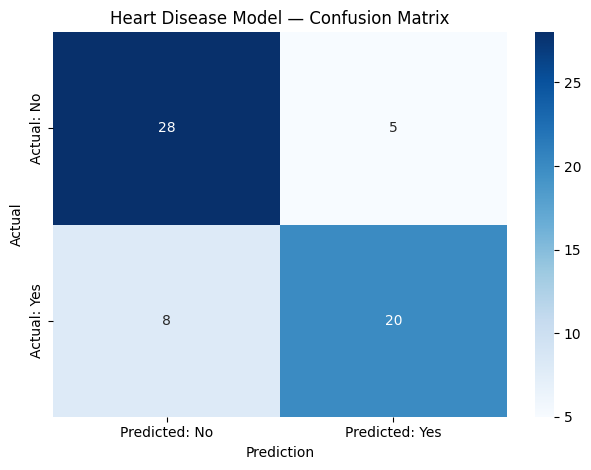

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.3f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.3f}")

if len(np.unique(y_test)) == 2:
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")

print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No disease", "Disease present"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted: No", "Predicted: Yes"],
    yticklabels=["Actual: No", "Actual: Yes"]
)
plt.title("Heart Disease Model — Confusion Matrix")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


## Step 9 — Test a prediction with four inputs


In [ ]:
sample_patient = pd.DataFrame([{
    "age": 50,
    "sex": 1,
    "cp": 0,
    "thalach": 150
}])

sample_prediction = int(model.predict(sample_patient)[0])
sample_probability = float(model.predict_proba(sample_patient)[0, 1])

print("Input attributes:")
display(sample_patient)
print("Predicted class:", sample_prediction,
      "(1 = disease present; 0 = no disease)")
print(f"Model-estimated probability for class 1: {sample_probability:.3f}")


Input attributes:


,age,sex,cp,thalach
0,50,1,0,150


Predicted class: 0 (1 = disease present; 0 = no disease)
Model-estimated probability for class 1: 0.083


## Step 10 — Save the trained model


In [ ]:
artifact = {
    "model": model,
    "features": required_features,
    "target_mapping": {"0": "No disease", "1": "Disease present"}
}
joblib.dump(artifact, "heart_disease_model.joblib")
print("Saved: heart_disease_model.joblib")


Saved: heart_disease_model.joblib
